In [22]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import numpy as np
from tqdm import tqdm

In [3]:
df = pd.read_csv("./Dataframes/processed_data.csv", encoding="utf-8", parse_dates=["timestamp"], index_col = 'timestamp')

In [4]:
df.head()

,source_file,altitude,cadence,enhanced_speed,heart_rate,position_lat,position_long,power,target_power,MESS_DATUM,TM_10,timestamp_berlin,day_of_week,hour_utc,hour_berlin,time_of_day
timestamp,,,,,,,,,,,,,,,,
2026-01-10 12:33:03+00:00,2026-01-10-13-32-12.fit,5.0,45,0.930,NaN,-138857456,1991775616,43,50.0,2026-01-10 12:40:00+00:00,1.45,2026-01-10 13:33:03+01:00,Saturday,12,13,Afternoon
2026-01-10 12:33:04+00:00,2026-01-10-13-32-12.fit,5.0,45,1.015,NaN,-138857440,1991775616,43,50.0,2026-01-10 12:40:00+00:00,1.45,2026-01-10 13:33:04+01:00,Saturday,12,13,Afternoon
2026-01-10 12:33:05+00:00,2026-01-10-13-32-12.fit,5.0,50,1.549,NaN,-138857312,1991775616,45,50.0,2026-01-10 12:40:00+00:00,1.45,2026-01-10 13:33:05+01:00,Saturday,12,13,Afternoon
2026-01-10 12:33:06+00:00,2026-01-10-13-32-12.fit,5.0,52,2.009,NaN,-138857104,1991775744,49,50.0,2026-01-10 12:40:00+00:00,1.45,2026-01-10 13:33:06+01:00,Saturday,12,13,Afternoon
2026-01-10 12:33:07+00:00,2026-01-10-13-32-12.fit,4.8,53,2.398,NaN,-138856880,1991775744,50,50.0,2026-01-10 12:40:00+00:00,1.45,2026-01-10 13:33:07+01:00,Saturday,12,13,Afternoon


In [5]:
import pandas as pd


def get_best_average(
    df: pd.DataFrame,
    metric: str,
    duration_seconds: int,
) -> float:
    """Find the highest rolling average of a metric over a given duration.

    Windows that span a gap in the index (missing timestamps) are
    excluded from the evaluation, since a full second-by-second index
    is assumed but not guaranteed to be complete.

    Args:
        df: DataFrame with a DatetimeIndex (one row per second) containing
            at least the column specified by `metric`.
        metric: Column name to analyze, e.g. "heart_rate" or "power".
        duration_seconds: Length of the rolling window in seconds.

    Returns:
        The highest average value of the metric over any window of the
        given duration.

    Raises:
        ValueError: If the metric column does not exist or no valid
            window could be found.
    """
    if metric not in df.columns:
        raise ValueError(f"Column '{metric}' not found in dataframe.")

    series = df[metric]

    # Reindex to a complete second-by-second range so gaps become NaN
    full_index = pd.date_range(
        start=series.index.min(), end=series.index.max(), freq="1s"
    )
    reindexed = series.reindex(full_index)

    # min_periods=duration_seconds ensures windows with any NaN are dropped
    rolling_avg = reindexed.rolling(
        window=duration_seconds, min_periods=duration_seconds
    ).mean()

    best_avg = rolling_avg.max()

    if pd.isna(best_avg):
        raise ValueError(
            f"No valid {duration_seconds}-second window found for '{metric}'."
        )

    return best_avg

In [6]:
get_best_average(df, 'heart_rate', 60)

np.float64(198.31666666666666)

In [7]:
get_best_average(df, 'power', 60)

np.float64(380.28333333333336)

In [35]:
def _format_duration_label(seconds: int) -> str:
    """Format a duration in seconds as a human-readable label.

    Args:
        seconds: Duration in seconds.

    Returns:
        A short label like "30s", "5m", "1h 30m".
    """
    if seconds < 60:
        return f"{seconds}s"
    minutes, remaining_seconds = divmod(seconds, 60)
    if minutes < 60:
        return f"{minutes}m" if remaining_seconds == 0 else f"{minutes}m{remaining_seconds}s"
    hours, remaining_minutes = divmod(minutes, 60)
    return f"{hours}h" if remaining_minutes == 0 else f"{hours}h{remaining_minutes}m"

def _compute_best_averages_vectorized(
    values: np.ndarray,
    durations: np.ndarray,
    show_progress: bool = True,
) -> np.ndarray:
    """Compute the best rolling average for each duration using vectorized ops.

    Uses the cumulative-sum trick to get windowed sums in O(n) per duration
    instead of relying on pandas rolling in a Python loop. NaNs (gaps in
    the original data) are propagated so windows spanning a gap are
    correctly excluded.

    Args:
        values: 1D array of metric values (may contain NaN for gaps).
        durations: 1D array of window sizes (in samples) to evaluate.

    Returns:
        1D array of best average values, one per duration. NaN if no valid
        window exists for that duration.
    """
    n = len(values)
    # Cumulative sum with a leading zero for O(1) windowed-sum lookups.
    # NaNs must be handled separately since np.cumsum propagates them.
    is_nan = np.isnan(values)
    clean_values = np.where(is_nan, 0.0, values)
    cumsum = np.concatenate([[0.0], np.cumsum(clean_values)])
    cumsum_nan_count = np.concatenate([[0], np.cumsum(is_nan.astype(int))])

    best_averages = np.full(len(durations), np.nan)

    iterator = (
        tqdm(enumerate(durations), total=len(durations), desc="Computing durations")
        if show_progress
        else enumerate(durations)
    )

    for idx, window in iterator:
        window = int(window)
        if window > n:
            continue

        window_sums = cumsum[window:] - cumsum[:-window]
        window_nan_counts = cumsum_nan_count[window:] - cumsum_nan_count[:-window]

        # Only consider windows without any NaN (i.e. no gap in the data)
        valid_mask = window_nan_counts == 0
        if not np.any(valid_mask):
            continue

        window_means = window_sums[valid_mask] / window
        best_averages[idx] = window_means.max()

    return best_averages


def build_duration_curve_data(
    df: pd.DataFrame,
    metric: str,
    min_duration: int = 1,
    max_duration: int | None = None,
) -> pd.DataFrame:
    """Compute best-average values across a log-spaced range of durations.

    Args:
        df: DataFrame with a DatetimeIndex (one row per second) containing
            at least the column specified by `metric`.
        metric: Column name to analyze, e.g. "heart_rate" or "power".
        min_duration: Shortest window duration in seconds.
        max_duration: Longest window duration in seconds. Defaults to the
            total duration of the dataframe in seconds.

    Returns:
        A DataFrame with columns "duration_seconds" and "best_value",
        sorted by duration.
    """
    if max_duration is None:
        max_duration = min(int((df.index.max() - df.index.min()).total_seconds()), 2 * 3600)

    series = df[metric]
    full_index = pd.date_range(
        start=series.index.min(), end=series.index.max(), freq="1s"
    )
    reindexed = series.reindex(full_index)
    values = reindexed.to_numpy(dtype=float)

    durations = np.arange(min_duration, max_duration + 1)
    best_values = _compute_best_averages_vectorized(values, durations, show_progress=True)

    valid_mask = ~np.isnan(best_values)
    return pd.DataFrame(
        {
            "duration_seconds": durations[valid_mask],
            "best_value": best_values[valid_mask],
        }
    )


def plot_duration_curve(
    df: pd.DataFrame,
    metric: str,
    min_duration: int = 1,
    max_duration: int | None = None,
    x_axis_exponent: float = 0.6,
) -> go.Figure:
    """Plot an interactive duration curve (best average vs. window duration).

    Uses a logarithmic x-axis so short durations are shown with high
    resolution while long durations remain readable without excessive
    granularity.

    Args:
        df: DataFrame with a DatetimeIndex (one row per second) containing
            at least the column specified by `metric`.
        metric: Column name to analyze, e.g. "heart_rate" or "power".
        min_duration: Shortest window duration in seconds.
        max_duration: Longest window duration in seconds. Defaults to the
            total duration of the dataframe in seconds.

    Returns:
        A Plotly Figure object.
    """
    curve_data = build_duration_curve_data(df, metric, min_duration, max_duration)
    curve_data["duration_label"] = curve_data["duration_seconds"].apply(
        _format_duration_label
    )

    
    transformed_x = curve_data["duration_seconds"] ** x_axis_exponent

    metric_label = "Heart Rate (bpm)" if metric == "heart_rate" else "Power (W)"
    title_label = "Heart Rate" if metric == "heart_rate" else "Power"
    line_color = "#d62728" if metric == "heart_rate" else "#1f77b4"
    fill_color = (
        "rgba(214, 39, 40, 0.15)" if metric == "heart_rate" else "rgba(31, 119, 180, 0.15)"
    )

    fig = go.Figure(
        data=go.Scatter(
            x=transformed_x,
            y=curve_data["best_value"],
            mode="lines",
            line=dict(color=line_color, width=2.5, shape="spline"),
            fill="tozeroy",
            fillcolor=fill_color,
            customdata=curve_data["duration_label"],
            hovertemplate=(
                "Duration: %{customdata}<br>"
                f"Best {title_label}: " + "%{y:.1f}<extra></extra>"
            ),
        )
    )

    max_seconds = int(curve_data["duration_seconds"].max())
    tick_candidates = [1, 5, 10, 15, 30, 60, 120, 300, 600, 900, 1200, 1800, 2700, 3600, 5400, 7200]
    tick_seconds = [t for t in tick_candidates if t <= max_seconds] or [max_seconds]
    tick_values = [t ** x_axis_exponent for t in tick_seconds]
    tick_labels = [_format_duration_label(t) for t in tick_seconds]

    fig.update_layout(
        title=f"{title_label} Duration Curve",
        xaxis_title="Duration",
        yaxis_title=f"Best average {metric_label}",
        template="plotly_white",
        hovermode="x unified",
        height=800,
    )

    fig.update_xaxes(
        type="linear",
        tickmode="array",
        tickvals=tick_values,
        ticktext=tick_labels,
    )
    fig.update_yaxes(rangemode="tozero")

    return fig

Computing durations: 100%|██████████| 7200/7200 [09:51<00:00, 12.17it/s]


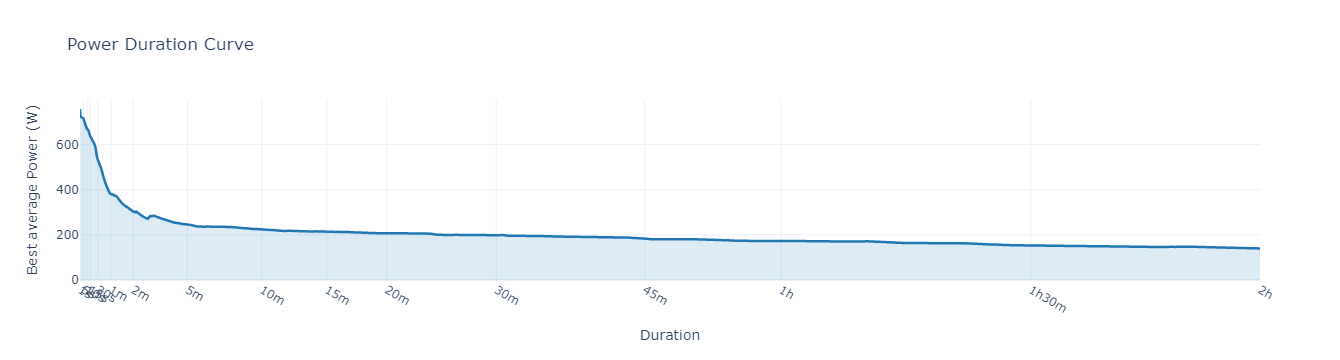

In [26]:
fig = plot_duration_curve(df, metric="power", max_duration=60*60*2)
fig.show()

Computing durations: 100%|██████████| 7200/7200 [01:26<00:00, 83.51it/s]


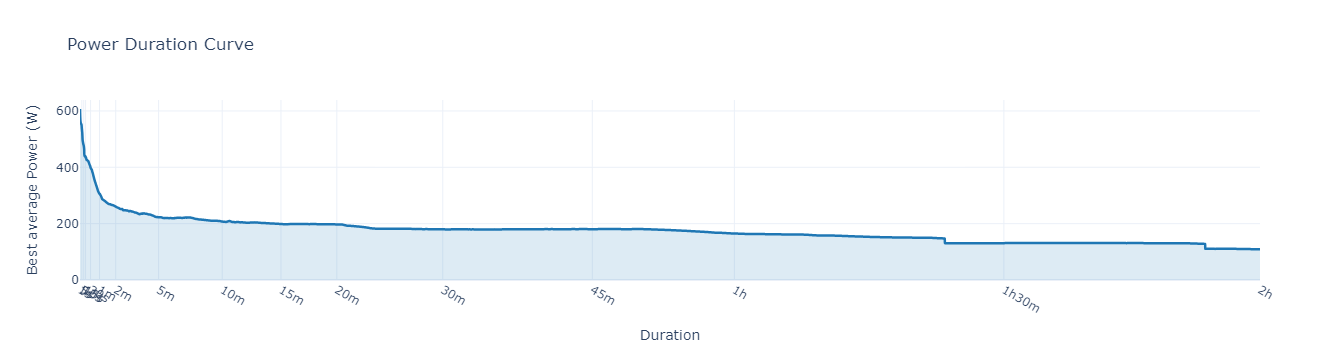

In [32]:
df['month'] = df.index.month
fig = plot_duration_curve(df[df.month == 3], metric="power", max_duration=60*60*2, x_axis_exponent = 0.85)
fig.show()

Computing durations: 100%|██████████| 7200/7200 [01:24<00:00, 85.00it/s]


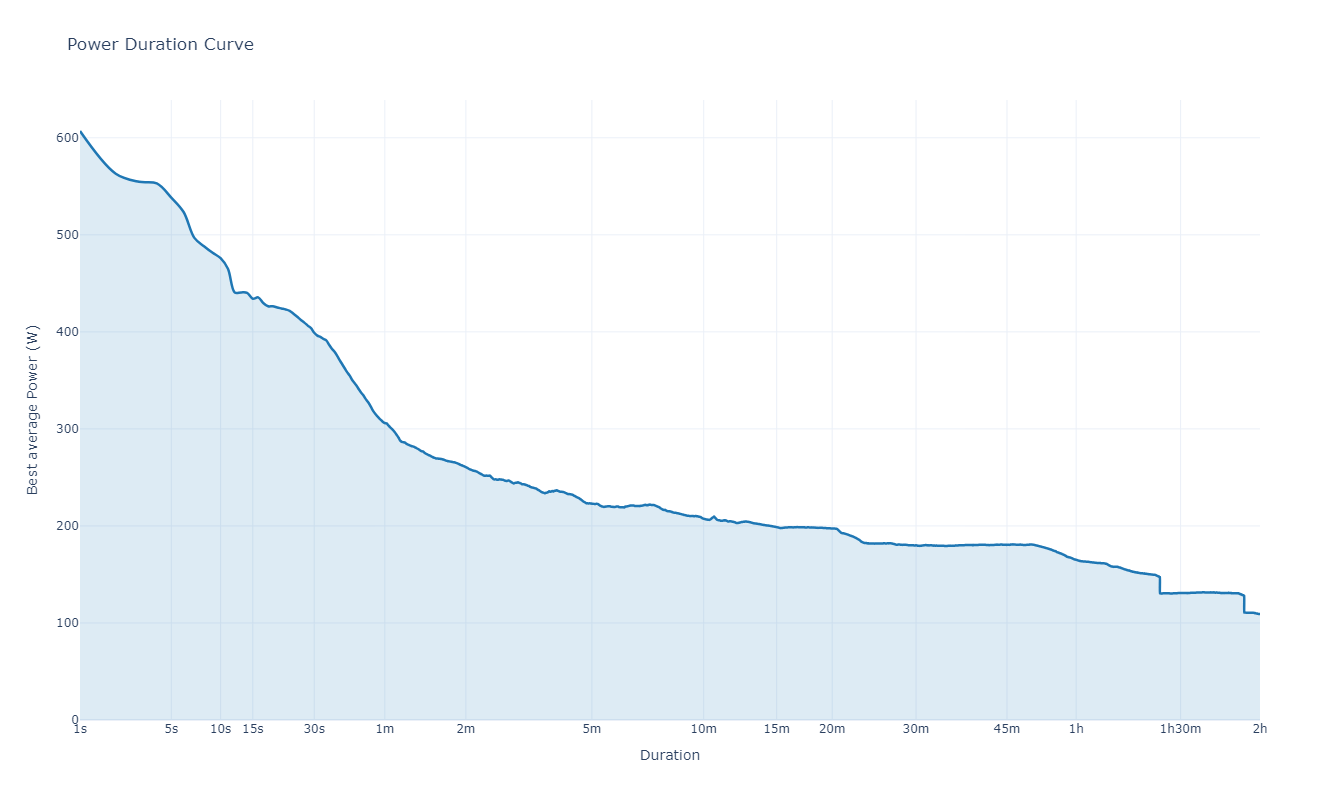

In [36]:
fig = plot_duration_curve(df[df.month == 3], metric="power", max_duration=60*60*2, x_axis_exponent = 0.2)
fig.show()